# Phase 6 — Multi-Contaminant Prediction

## Objective
Develop machine-learning models to predict the concentrations of eight core groundwater chemical parameters using temporal and geographical context.

## Core prediction targets
1. Potential of Hydrogen (pH)
2. Electrical Conductivity (μS/cm)
3. Chloride (mg/L)
4. Bicarbonate (mg/L)
5. Sulphate (mg/L)
6. Calcium (mg/L)
7. Magnesium (mg/L)
8. Sodium (mg/L)

## Modelling strategy
- Begin with context-only predictors: temporal features, state, district and geographical coordinates.
- Keep chemical target values out of the predictor set to avoid target leakage.
- Use spatial-group-aware validation so records from the same provisional spatial group do not appear in both training and testing.
- Evaluate each target separately because their units, distributions and prediction difficulty differ.
- Compare suitable baseline models before selecting stronger models.
- Report target-wise performance rather than relying on one combined score.

## Important limitations
- Provisional spatial groups are based on the location-identification work in Phase 3; they are not confirmed well identities.
- Predictions represent model estimates, not laboratory measurements.
- Model performance must be interpreted in light of uneven geographic and temporal sampling.

## Expected outputs
- Target and predictor readiness assessment.
- Spatially separated train/test datasets.
- Baseline and improved regression models.
- Target-wise evaluation metrics and diagnostic plots.
- Saved model artifacts and prediction results.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Locate the project root whether the notebook runs from the project
# directory or from the notebooks directory.
cwd = Path.cwd()

if (cwd / "reports").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "reports").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Run this notebook from the project or notebooks directory."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "reports"
    / "feature_engineering"
    / "regression_core_8_targets.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

model_df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully")
print("-" * 55)
print(f"File: {DATA_PATH.name}")
print(f"Rows: {len(model_df):,}")
print(f"Columns: {len(model_df.columns):,}")
print(f"Memory usage: {model_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

print("\nFirst 10 column names:")
print(model_df.columns[:10].tolist())

print("\nLast 10 column names:")
print(model_df.columns[-10:].tolist())

Dataset loaded successfully
-------------------------------------------------------
File: regression_core_8_targets.csv
Rows: 122,713
Columns: 27
Memory usage: 108.02 MB

First 10 column names:
['_record_id', '_source_file', '_source_row', '_parsed_date', '_provisional_station_id', '_provisional_location_candidate_id', '_spatial_group_id', '_geo_grid_id', '_latitude', '_longitude']

Last 10 column names:
['_dayofyear_sin', '_dayofyear_cos', 'Potential of Hydrogen (pH)', 'Electric Conductivity (μS/cm)', 'Chloride (mg/L)', 'Bicarbonate (mg/L)', 'Sulphate (mg/L)', 'Calcium (mg/L)', 'Magnesium (mg/L)', 'Sodium (mg/L)']


In [4]:
TARGETS = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)"
]

missing_targets = [col for col in TARGETS if col not in model_df.columns]

if missing_targets:
    print("Missing target columns:", missing_targets)
    raise KeyError("Target column names still do not match the dataset.")

target_rows = []

for col in TARGETS:
    values = pd.to_numeric(model_df[col], errors="coerce")
    valid = values.dropna()

    target_rows.append({
        "Target": col,
        "Valid records": len(valid),
        "Missing records": int(values.isna().sum()),
        "Minimum": valid.min(),
        "Median": valid.median(),
        "Mean": valid.mean(),
        "95th percentile": valid.quantile(0.95),
        "Maximum": valid.max(),
        "Skewness": valid.skew(),
        "Zero values": int((valid == 0).sum()),
        "Negative values": int((valid < 0).sum())
    })

target_audit = pd.DataFrame(target_rows).set_index("Target")

print("CORE TARGET DISTRIBUTION AUDIT")
display(target_audit.round(3))

CORE TARGET DISTRIBUTION AUDIT


,Valid records,Missing records,Minimum,Median,Mean,95th percentile,Maximum,Skewness,Zero values,Negative values
Target,,,,,,,,,,
Potential of Hydrogen (pH),122713,0,0.52,7.850,7.823,8.500,10.99,-0.626,0,0
Electric Conductivity (μS/cm),122713,0,0.00,865.000,1319.230,3920.000,472666.00,91.381,1,0
Chloride (mg/L),122713,0,0.00,78.000,204.079,780.000,20000.00,10.657,6,0
Bicarbonate (mg/L),122713,0,0.00,267.638,296.202,634.000,293451.00,323.572,635,0
Sulphate (mg/L),122713,0,0.00,36.000,96.172,382.000,17179.00,12.570,5441,0
Calcium (mg/L),122713,0,0.00,48.000,65.096,170.000,4856.00,8.996,71,0
Magnesium (mg/L),122713,0,0.00,29.260,44.278,129.228,2443.00,7.928,125,0
Sodium (mg/L),122713,0,0.00,61.000,144.529,560.000,9750.00,7.842,107,0


In [5]:
# Context-only predictors for the first modelling baseline.
NUMERIC_FEATURES = [
    "_year_index",
    "_month_sin",
    "_month_cos",
    "_dayofyear_sin",
    "_dayofyear_cos",
    "_latitude",
    "_longitude",
    "_coordinates_missing"
]

CATEGORICAL_FEATURES = [
    "_state_feature",
    "_district_feature"
]

GROUP_COLUMN = "_spatial_group_id"

required_columns = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
    + [GROUP_COLUMN]
)

missing_columns = [
    col for col in required_columns
    if col not in model_df.columns
]

if missing_columns:
    raise KeyError(f"Required modelling columns missing: {missing_columns}")

print("PREDICTOR READINESS")
print("-" * 55)

print("\nNumeric features:")
for col in NUMERIC_FEATURES:
    print(f"{col:28s} | dtype={model_df[col].dtype} | missing={model_df[col].isna().sum():,}")

print("\nCategorical features:")
for col in CATEGORICAL_FEATURES:
    print(
        f"{col:28s} | dtype={model_df[col].dtype} "
        f"| missing={model_df[col].isna().sum():,} "
        f"| unique={model_df[col].nunique(dropna=True):,}"
    )

print("\nSPATIAL GROUP AUDIT")
print("-" * 55)

group_sizes = model_df[GROUP_COLUMN].dropna().value_counts()

print(f"Records: {len(model_df):,}")
print(f"Records with a spatial group: {model_df[GROUP_COLUMN].notna().sum():,}")
print(f"Records without a spatial group: {model_df[GROUP_COLUMN].isna().sum():,}")
print(f"Distinct spatial groups: {group_sizes.size:,}")
print(f"Groups with one record: {(group_sizes == 1).sum():,}")
print(f"Groups with multiple records: {(group_sizes > 1).sum():,}")
print(f"Largest group size: {group_sizes.max() if len(group_sizes) else 0:,}")

if len(group_sizes):
    print("\nSpatial group size distribution:")
    display(
        group_sizes.describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        ).to_frame("Records per group").round(2)
    )

PREDICTOR READINESS
-------------------------------------------------------

Numeric features:
_year_index                  | dtype=int64 | missing=0
_month_sin                   | dtype=float64 | missing=0
_month_cos                   | dtype=float64 | missing=0
_dayofyear_sin               | dtype=float64 | missing=0
_dayofyear_cos               | dtype=float64 | missing=0
_latitude                    | dtype=float64 | missing=98
_longitude                   | dtype=float64 | missing=98
_coordinates_missing         | dtype=int64 | missing=0

Categorical features:
_state_feature               | dtype=str | missing=0 | unique=31
_district_feature            | dtype=str | missing=0 | unique=589

SPATIAL GROUP AUDIT
-------------------------------------------------------
Records: 122,713
Records with a spatial group: 122,713
Records without a spatial group: 0
Distinct spatial groups: 21,791
Groups with one record: 4,750
Groups with multiple records: 17,041
Largest group size: 21

Spatial

,Records per group
count,21791.00
mean,5.63
std,4.75
min,1.00
25%,2.00
50%,4.00
75%,8.00
90%,14.00
95%,16.00
99%,18.00


In [6]:
# Inspect upper-tail values before selecting regression transformations
# or deciding how to handle extreme observations.

metadata_cols = [
    "_record_id",
    "_source_file",
    "_source_row",
    "_state_feature",
    "_district_feature",
    "_latitude",
    "_longitude",
    "_spatial_group_id"
]

for col in TARGETS:
    values = pd.to_numeric(model_df[col], errors="coerce")

    print("\n" + "=" * 90)
    print(f"TARGET: {col}")
    print("=" * 90)

    quantile_table = values.quantile(
        [0.95, 0.99, 0.995, 0.999, 1.00]
    ).to_frame("Value")

    quantile_table.index = [
        "95th percentile",
        "99th percentile",
        "99.5th percentile",
        "99.9th percentile",
        "Maximum"
    ]

    display(quantile_table.round(4))

    print("Five highest observations with source information:")

    top_indices = values.nlargest(5).index

    display(
        model_df.loc[
            top_indices,
            metadata_cols + [col]
        ].sort_values(col, ascending=False).reset_index(drop=True)
    )


TARGET: Potential of Hydrogen (pH)


,Value
95th percentile,8.50
99th percentile,8.90
99.5th percentile,9.01
99.9th percentile,9.50
Maximum,10.99


Five highest observations with source information:


,_record_id,_source_file,_source_row,_state_feature,_district_feature,_latitude,_longitude,_spatial_group_id,Potential of Hydrogen (pH)
0,gwq_chemical_parameter_manual_cgwb_rj_1961_202...,gwq_chemical_parameter_manual_cgwb_rj_1961_2025,11179,rajasthan,bundi,25.472222,75.554167,rajasthan|bundi|satur|site|25.47222|75.55417,10.99
1,gwq_chemical_parameter_manual_cgwb_ka_1961_202...,gwq_chemical_parameter_manual_cgwb_ka_1961_2025,9149,karnataka,tumkur,13.450278,76.462222,karnataka|tumkur|mysorappan palya|site|13.4502...,10.92
2,gwq_chemical_parameter_manual_cgwb_mp_1961_202...,gwq_chemical_parameter_manual_cgwb_mp_1961_2025,9556,madhya pradesh,mandla,22.792778,80.411111,madhya pradesh|mandla|khari|site|22.79278|80.4...,10.86
3,gwq_chemical_parameter_manual_cgwb_rj_1961_202...,gwq_chemical_parameter_manual_cgwb_rj_1961_2025,3134,rajasthan,bundi,25.663889,75.438889,rajasthan|bundi|devakhera|site|25.66389|75.43889,10.73
4,gwq_chemical_parameter_manual_cgwb_kl_1961_202...,gwq_chemical_parameter_manual_cgwb_kl_1961_2025,1777,kerala,ernakulam,10.022222,76.307500,kerala|ernakulam|edapally|site|10.02222|76.3075,10.70



TARGET: Electric Conductivity (μS/cm)


,Value
95th percentile,3920.00
99th percentile,8010.00
99.5th percentile,10100.00
99.9th percentile,16735.76
Maximum,472666.00


... (22 outputs left out)


TARGET: Sodium (mg/L)


,Value
95th percentile,560.000
99th percentile,1280.000
99.5th percentile,1675.000
99.9th percentile,3087.592
Maximum,9750.000


Five highest observations with source information:


,_record_id,_source_file,_source_row,_state_feature,_district_feature,_latitude,_longitude,_spatial_group_id,Sodium (mg/L)
0,gwq_chemical_parameter_manual_cgwb_rj_1961_202...,gwq_chemical_parameter_manual_cgwb_rj_1961_2025,2241,rajasthan,barmer,26.275000,71.305556,rajasthan|barmer|bisukalan|site|26.275|71.30556,9750.0
1,gwq_chemical_parameter_manual_cgwb_rj_1961_202...,gwq_chemical_parameter_manual_cgwb_rj_1961_2025,2239,rajasthan,barmer,26.275000,71.305556,rajasthan|barmer|bisukalan|site|26.275|71.30556,9725.0
2,gwq_chemical_parameter_manual_cgwb_tn_1961_202...,gwq_chemical_parameter_manual_cgwb_tn_1961_2025,3689,tamil nadu,pudukkottai,9.933333,79.141667,tamil nadu|pudukkottai|mimisal1|site|9.93333|7...,9500.0
3,gwq_chemical_parameter_manual_cgwb_rj_1961_202...,gwq_chemical_parameter_manual_cgwb_rj_1961_2025,2240,rajasthan,barmer,26.275000,71.305556,rajasthan|barmer|bisukalan|site|26.275|71.30556,9280.0
4,gwq_chemical_parameter_manual_cgwb_tn_1961_202...,gwq_chemical_parameter_manual_cgwb_tn_1961_2025,3684,tamil nadu,pudukkottai,9.933333,79.141667,tamil nadu|pudukkottai|mimisal1|site|9.93333|7...,8650.0


In [7]:
MASTER_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "groundwater_master_processed.csv"
)

if not MASTER_PATH.exists():
    raise FileNotFoundError(f"Master dataset not found: {MASTER_PATH}")

# Identify the observation with the maximum electrical conductivity.
ec_col = "Electric Conductivity (μS/cm)"
max_ec_idx = pd.to_numeric(
    model_df[ec_col], errors="coerce"
).idxmax()

suspect_id = model_df.loc[max_ec_idx, "_record_id"]

print("SUSPECT RECORD")
print("-" * 55)
print("Record ID:", suspect_id)
print("Source file:", model_df.loc[max_ec_idx, "_source_file"])
print("Source row:", model_df.loc[max_ec_idx, "_source_row"])
print("State:", model_df.loc[max_ec_idx, "_state_feature"])
print("District:", model_df.loc[max_ec_idx, "_district_feature"])

# Load the integrated master and retrieve the original record.
master_df = pd.read_csv(MASTER_PATH, low_memory=False)

suspect_row = master_df[
    master_df["_record_id"].astype(str) == str(suspect_id)
]

if suspect_row.empty:
    raise ValueError("Suspect record was not found in the integrated master.")

# Select useful metadata, original chemical fields and QC flags.
metadata_terms = [
    "record_id", "source_file", "source_row",
    "station", "state", "district", "date", "time",
    "latitude", "longitude"
]

chemical_terms = [
    "hydrogen", "conductivity", "chloride",
    "bicarbonate", "sulphate", "sulfate",
    "calcium", "magnesium", "sodium",
    "hardness", "alkalinity", "tds"
]

quality_terms = [
    "flag", "quality", "outlier", "invalid",
    "negative", "zero", "parse"
]

selected_columns = []

for col in master_df.columns:
    name = col.lower()

    is_metadata = any(term in name for term in metadata_terms)
    is_chemical = any(term in name for term in chemical_terms)
    is_relevant_flag = (
        any(term in name for term in quality_terms)
        and is_chemical
    )

    if is_metadata or is_chemical or is_relevant_flag:
        selected_columns.append(col)

print("\nORIGINAL INTEGRATED MASTER RECORD")
print("-" * 55)
display(suspect_row[selected_columns].T)

SUSPECT RECORD
-------------------------------------------------------
Record ID: gwq_chemical_parameter_manual_cgwb_up_1961_2025::6605
Source file: gwq_chemical_parameter_manual_cgwb_up_1961_2025
Source row: 6605
State: uttar pradesh
District: farrukhabad

ORIGINAL INTEGRATED MASTER RECORD
-------------------------------------------------------


,166341
Station,Shamsabad2
State LGD Code,9
State,Uttar Pradesh
District LGD Code,141
District,FARRUKHABAD
...,...
_qc__iqr_outlier__Sulphate (mg/L),False
_qc__iqr_outlier__Total Hardness (mgCaCO3/L),True
_qc__iqr_outlier__Calcium (mg/L),True
_qc__iqr_outlier__Magnesium (mg/L),True


In [8]:
important_terms = [
    "hydrogen",
    "conductivity",
    "chloride",
    "bicarbonate",
    "sulphate",
    "sulfate",
    "calcium",
    "magnesium",
    "sodium",
    "hardness",
    "alkalinity",
    "tds",
    "iron"
]

metadata_terms = [
    "record_id",
    "source_file",
    "source_row",
    "station",
    "state",
    "district",
    "data acquisition time",
    "latitude",
    "longitude"
]

relevant_cols = []

for col in master_df.columns:
    name = col.lower()

    if (
        any(term in name for term in important_terms)
        or any(term in name for term in metadata_terms)
    ):
        relevant_cols.append(col)

print("COMPLETE SUSPECT RECORD — RELEVANT FIELDS")
print("=" * 75)

for col in relevant_cols:
    value = suspect_row.iloc[0][col]
    print(f"{col}: {value}")

COMPLETE SUSPECT RECORD — RELEVANT FIELDS
Station: Shamsabad2
State LGD Code: 9
State: Uttar Pradesh
District LGD Code: 141
District: FARRUKHABAD
Latitude: 27.46944444
Longitude: 79.435
Data Acquisition Time: 25-05-2000 00:00
Potential of Hydrogen (pH): 8.0
Electric Conductivity (μS/cm): 472666.0
Bicarbonate (mg/L): 293451.0
Total Alkalinity (mg/L as CaCO3): nan
Chloride (mg/L): 117.0
Sulphate (mg/L): 147.2
Total Hardness (mgCaCO3/L): 240295.0
Calcium (mg/L): 4856.0
Magnesium (mg/L): 2443.0
Sodium (mg/L): 2042.0
Iron(mg/L): nan
_source_file: gwq_chemical_parameter_manual_cgwb_up_1961_2025
_source_row: 6605
_station_norm: shamsabad2
_state_norm: uttar pradesh
_district_norm: farrukhabad
_provisional_station_id: uttar pradesh|farrukhabad|shamsabad2
_record_id: gwq_chemical_parameter_manual_cgwb_up_1961_2025::6605
_qc__Potential of Hydrogen (pH)__negative: False
_qc__Potential of Hydrogen (pH)__zero: False
_qc__Potential of Hydrogen (pH)__nonfinite: False
_qc__Potential of Hydrogen (pH)__

In [9]:
from pathlib import Path

EXTRACTED_DIR = PROJECT_ROOT / "data" / "extracted"

source_stem = str(model_df.loc[max_ec_idx, "_source_file"])

raw_files = [
    p for p in EXTRACTED_DIR.glob("*.csv")
    if p.stem.lower() == source_stem.lower()
]

if len(raw_files) != 1:
    raise FileNotFoundError(
        f"Expected one original CSV for {source_stem}, "
        f"but found {len(raw_files)}: {raw_files}"
    )

raw_path = raw_files[0]

raw_df = pd.read_csv(
    raw_path,
    dtype=str,
    keep_default_na=False,
    low_memory=False
)

print("ORIGINAL SOURCE FILE:", raw_path.name)
print("Original rows:", f"{len(raw_df):,}")

# Identify original metadata columns.
station_col = next(
    (c for c in raw_df.columns if c.strip().lower() in ["station", "station name"]),
    None
)
date_col = next(
    (c for c in raw_df.columns if "data acquisition time" in c.strip().lower()),
    None
)
lat_col = next(
    (c for c in raw_df.columns if "latitude" in c.strip().lower()),
    None
)
lon_col = next(
    (c for c in raw_df.columns if "longitude" in c.strip().lower()),
    None
)

if not all([station_col, date_col]):
    raise KeyError(
        f"Could not identify original metadata columns. "
        f"Available columns: {raw_df.columns.tolist()}"
    )

# Match using station, date and coordinates.
suspect_date = pd.to_datetime(
    "25-05-2000 00:00",
    format="mixed",
    dayfirst=True
)

raw_dates = pd.to_datetime(
    raw_df[date_col].astype(str).str.strip(),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

mask = (
    raw_df[station_col].astype(str).str.strip().str.casefold()
    == "shamsabad2"
) & raw_dates.eq(suspect_date)

if lat_col and lon_col:
    raw_lat = pd.to_numeric(raw_df[lat_col], errors="coerce")
    raw_lon = pd.to_numeric(raw_df[lon_col], errors="coerce")

    mask &= (
        np.isclose(raw_lat, 27.46944444, atol=0.00001, equal_nan=False)
        & np.isclose(raw_lon, 79.435, atol=0.00001, equal_nan=False)
    )

raw_matches = raw_df.loc[mask]

print("\nMATCHING OBSERVATIONS:", len(raw_matches))

if len(raw_matches):
    print("\nORIGINAL RAW CSV RECORD(S)")
    display(raw_matches.T)
else:
    print("No exact metadata match found.")
    print("\nRows near the recorded source row number:")
    source_row = int(model_df.loc[max_ec_idx, "_source_row"])

    display(
        raw_df.iloc[
            max(0, source_row - 2):min(len(raw_df), source_row + 2)
        ].T
    )

# Show all QC flags for this observation in the integrated master.
qc_columns = [
    c for c in master_df.columns
    if c.startswith("_qc__")
]

print("\nQUALITY CONTROL FLAGS FOR THIS RECORD")
display(suspect_row[qc_columns].T)

ORIGINAL SOURCE FILE: gwq_chemical_parameter_manual_cgwb_up_1961_2025.csv
Original rows: 7,329

MATCHING OBSERVATIONS: 1

ORIGINAL RAW CSV RECORD(S)


,6605
SlNo,6606
Station,Shamsabad2
Agency,CGWB
State LGD Code,9
State,Uttar Pradesh
District LGD Code,141
District,FARRUKHABAD
Tehsil,SHAMSABAD
Block,SHAMSABAD
Village,Shamsabad



QUALITY CONTROL FLAGS FOR THIS RECORD


,166341
_qc__Potential of Hydrogen (pH)__negative,False
_qc__Potential of Hydrogen (pH)__zero,False
_qc__Potential of Hydrogen (pH)__nonfinite,False
_qc__Potential of Hydrogen (pH)__invalid_parse,False
_qc__Electric Conductivity (μS/cm)__negative,False
...,...
_qc__iqr_outlier__Nickel (mg/L),False
_qc__iqr_outlier__Cadmium (mg/L),False
_qc__iqr_outlier__Chromium (mg/L),False
_qc__flag_count,6


In [10]:
from sklearn.model_selection import GroupShuffleSplit

FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Preserve the original observations.
X = model_df[FEATURE_COLUMNS].copy()
y = model_df[TARGETS].apply(pd.to_numeric, errors="coerce")
groups = model_df[GROUP_COLUMN].astype(str)

# Verify modelling readiness.
assert not y.isna().any().any(), "Missing target values detected."
assert groups.notna().all(), "Missing spatial group IDs detected."

# Split by spatial group, not by individual record.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("SPATIAL TRAIN/TEST SPLIT")
print("=" * 55)

print(f"Total records:       {len(model_df):,}")
print(f"Training records:    {len(X_train):,}")
print(f"Testing records:     {len(X_test):,}")

print(f"\nTotal spatial groups: {groups.nunique():,}")
print(f"Training groups:      {len(train_groups):,}")
print(f"Testing groups:       {len(test_groups):,}")
print(f"Overlapping groups:   {len(train_groups.intersection(test_groups)):,}")

print(f"\nTraining proportion: {len(X_train) / len(X):.2%}")
print(f"Testing proportion:  {len(X_test) / len(X):.2%}")

train_states = set(model_df.iloc[train_idx]["_state_feature"])
test_states = set(model_df.iloc[test_idx]["_state_feature"])

print(f"\nStates in training: {len(train_states)}")
print(f"States in testing:  {len(test_states)}")
print("States absent from test:", sorted(train_states - test_states))

assert len(train_groups.intersection(test_groups)) == 0
assert len(train_idx) + len(test_idx) == len(model_df)

print("\nSpatial separation verified successfully.")

SPATIAL TRAIN/TEST SPLIT
Total records:       122,713
Training records:    98,005
Testing records:     24,708

Total spatial groups: 21,791
Training groups:      17,432
Testing groups:       4,359
Overlapping groups:   0

Training proportion: 79.87%
Testing proportion:  20.13%

States in training: 31
States in testing:  30
States absent from test: ['chandigarh']

Spatial separation verified successfully.


In [11]:
PH_TARGET = "Potential of Hydrogen (pH)"

CONCENTRATION_TARGETS = [
    target for target in TARGETS
    if target != PH_TARGET
]

TARGET_TRANSFORMS = {
    target: "identity" if target == PH_TARGET else "log1p"
    for target in TARGETS
}

# Check that log1p is valid for every concentration target.
for target in CONCENTRATION_TARGETS:
    if (y_train[target] < 0).any() or (y_test[target] < 0).any():
        raise ValueError(f"Negative values found in {target}; review before log1p.")

# Create transformed copies, retaining original-scale targets.
y_train_transformed = y_train.copy()
y_test_transformed = y_test.copy()

for target in CONCENTRATION_TARGETS:
    y_train_transformed[target] = np.log1p(y_train[target])
    y_test_transformed[target] = np.log1p(y_test[target])

transform_summary = pd.DataFrame({
    "Target": TARGETS,
    "Transformation": [TARGET_TRANSFORMS[t] for t in TARGETS],
    "Training minimum (model scale)": [
        y_train_transformed[t].min() for t in TARGETS
    ],
    "Training maximum (model scale)": [
        y_train_transformed[t].max() for t in TARGETS
    ]
}).set_index("Target")

print("TARGET TRANSFORMATION SUMMARY")
display(transform_summary.round(4))

print("\nOriginal-scale training targets retained:", y_train.shape)
print("Transformed training targets prepared:", y_train_transformed.shape)
print("Original-scale testing targets retained:", y_test.shape)

TARGET TRANSFORMATION SUMMARY


,Transformation,Training minimum (model scale),Training maximum (model scale)
Target,,,
Potential of Hydrogen (pH),identity,0.52,10.9900
Electric Conductivity (μS/cm),log1p,0.00,13.0661
Chloride (mg/L),log1p,0.00,9.9035
Bicarbonate (mg/L),log1p,0.00,12.5895
Sulphate (mg/L),log1p,0.00,9.0896
Calcium (mg/L),log1p,0.00,8.4882
Magnesium (mg/L),log1p,0.00,7.8014
Sodium (mg/L),log1p,0.00,9.1851



Original-scale training targets retained: (98005, 8)
Transformed training targets prepared: (98005, 8)
Original-scale testing targets retained: (24708, 8)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)
from sklearn.base import clone
from time import perf_counter

# Numeric feature preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical feature preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=5
    ))
])

# Combine both preprocessing pipelines.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

# Leakage check
assert not set(FEATURE_COLUMNS).intersection(TARGETS)

print("PREPROCESSING CONFIGURATION")
print("-" * 55)
print("Numeric features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Categorical encoding: OneHotEncoder")
print("Rare category handling: min_frequency=5")
print("Numeric missing-value handling: Median imputation")
print("Unknown categories: Ignored safely")
print("\nTarget leakage check: PASSED")
print("Preprocessing pipeline is ready.")

PREPROCESSING CONFIGURATION
-------------------------------------------------------
Numeric features: 8
Categorical features: 2
Categorical encoding: OneHotEncoder
Rare category handling: min_frequency=5
Numeric missing-value handling: Median imputation
Unknown categories: Ignored safely

Target leakage check: PASSED
Preprocessing pipeline is ready.


In [13]:
trained_models = {}
training_times = {}

MODEL_SETTINGS = {
    "n_estimators": 150,
    "max_features": 0.7,
    "min_samples_leaf": 3,
    "random_state": 42,
    "n_jobs": -1
}

print("RANDOM FOREST TRAINING")
print("=" * 65)

for target in TARGETS:

    print(f"\nTraining: {target}")
    start_time = perf_counter()

    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("regressor", RandomForestRegressor(**MODEL_SETTINGS))
    ])

    model.fit(
        X_train,
        y_train_transformed[target]
    )

    elapsed = perf_counter() - start_time

    trained_models[target] = model
    training_times[target] = elapsed

    print(f"Completed in {elapsed:.2f} seconds")

print("\n" + "=" * 65)
print("ALL EIGHT MODELS TRAINED SUCCESSFULLY")

training_summary = pd.DataFrame({
    "Target": TARGETS,
    "Model": ["Random Forest"] * len(TARGETS),
    "Trees": [MODEL_SETTINGS["n_estimators"]] * len(TARGETS),
    "Training time (seconds)": [
        training_times[t] for t in TARGETS
    ]
}).set_index("Target")

display(training_summary.round(2))

RANDOM FOREST TRAINING

Training: Potential of Hydrogen (pH)
Completed in 126.90 seconds

Training: Electric Conductivity (μS/cm)
Completed in 191.27 seconds

Training: Chloride (mg/L)
Completed in 190.15 seconds

Training: Bicarbonate (mg/L)
Completed in 172.18 seconds

Training: Sulphate (mg/L)
Completed in 178.15 seconds

Training: Calcium (mg/L)
Completed in 172.42 seconds

Training: Magnesium (mg/L)
Completed in 185.17 seconds

Training: Sodium (mg/L)
Completed in 185.76 seconds

ALL EIGHT MODELS TRAINED SUCCESSFULLY


,Model,Trees,Training time (seconds)
Target,,,
Potential of Hydrogen (pH),Random Forest,150,126.90
Electric Conductivity (μS/cm),Random Forest,150,191.27
Chloride (mg/L),Random Forest,150,190.15
Bicarbonate (mg/L),Random Forest,150,172.18
Sulphate (mg/L),Random Forest,150,178.15
Calcium (mg/L),Random Forest,150,172.42
Magnesium (mg/L),Random Forest,150,185.17
Sodium (mg/L),Random Forest,150,185.76


In [14]:
evaluation_rows = []
prediction_store = {}

for target in TARGETS:

    # Model prediction on the transformed scale
    predicted_transformed = trained_models[target].predict(X_test)

    # Convert predictions back to original units.
    if TARGET_TRANSFORMS[target] == "log1p":
        predicted_original = np.expm1(predicted_transformed)
    else:
        predicted_original = predicted_transformed

    actual_original = y_test[target].to_numpy()

    # Median baseline, calculated from training data only.
    baseline_value = y_train_transformed[target].median()

    baseline_transformed = np.full(
        len(y_test),
        baseline_value
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        baseline_original = np.expm1(baseline_transformed)
    else:
        baseline_original = baseline_transformed

    # Original-scale evaluation
    model_mae = mean_absolute_error(
        actual_original, predicted_original
    )

    model_rmse = np.sqrt(
        mean_squared_error(actual_original, predicted_original)
    )

    baseline_mae = mean_absolute_error(
        actual_original, baseline_original
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_original, baseline_original)
    )

    # Evaluation on the model's training transformation scale
    model_scale_mae = mean_absolute_error(
        y_test_transformed[target],
        predicted_transformed
    )

    model_scale_rmse = np.sqrt(
        mean_squared_error(
            y_test_transformed[target],
            predicted_transformed
        )
    )

    skill = (
        1 - model_mae / baseline_mae
        if baseline_mae != 0 else np.nan
    )

    evaluation_rows.append({
        "Target": target,
        "MAE": model_mae,
        "RMSE": model_rmse,
        "Median AE": median_absolute_error(
            actual_original, predicted_original
        ),
        "R2": r2_score(actual_original, predicted_original),
        "Baseline MAE": baseline_mae,
        "Baseline RMSE": baseline_rmse,
        "MAE skill vs baseline": skill,
        "Model-scale MAE": model_scale_mae,
        "Model-scale RMSE": model_scale_rmse
    })

    prediction_store[target] = pd.DataFrame({
        "Actual": actual_original,
        "Predicted": predicted_original
    }, index=y_test.index)

evaluation_df = pd.DataFrame(evaluation_rows).set_index("Target")

print("SPATIAL TEST-SET MODEL EVALUATION")
print("=" * 75)
display(evaluation_df.round(4))

print("\nInterpretation:")
print("- MAE and RMSE are expressed in each target's original units.")
print("- R2 measures explained variance; negative values are possible.")
print("- MAE skill above zero means the model beat the median baseline.")
print("- Model-scale metrics measure error after the selected transformation.")

SPATIAL TEST-SET MODEL EVALUATION


,MAE,RMSE,Median AE,R2,Baseline MAE,Baseline RMSE,MAE skill vs baseline,Model-scale MAE,Model-scale RMSE
Target,,,,,,,,,
Potential of Hydrogen (pH),0.2255,0.3227,0.1675,0.4828,0.3373,0.4500,0.3316,0.2255,0.3227
Electric Conductivity (μS/cm),646.9939,1499.4387,282.8351,0.2304,821.4079,1765.1881,0.2123,0.4791,0.6341
Chloride (mg/L),143.9307,435.9246,44.6800,0.1492,169.4742,489.1434,0.1507,0.7629,0.9735
Bicarbonate (mg/L),100.7022,148.8788,68.9137,0.3639,138.2884,187.8475,0.2718,0.4077,0.5677
Sulphate (mg/L),70.8188,239.5333,20.2080,0.1204,84.4484,262.7893,0.1614,0.8913,1.1632
Calcium (mg/L),31.7489,59.8059,17.4199,0.1523,37.2184,67.2069,0.1470,0.4984,0.6534
Magnesium (mg/L),24.6047,57.0753,11.7902,0.1835,29.9672,65.0310,0.1789,0.5704,0.7552
Sodium (mg/L),90.9004,250.1224,28.4190,0.2275,115.6292,295.7282,0.2139,0.6827,0.8934



Interpretation:
- MAE and RMSE are expressed in each target's original units.
- R2 measures explained variance; negative values are possible.
- MAE skill above zero means the model beat the median baseline.
- Model-scale metrics measure error after the selected transformation.


In [15]:
diagnostic_rows = []
range_rows = []

for target in TARGETS:
    actual = prediction_store[target]["Actual"]
    predicted = prediction_store[target]["Predicted"]

    residual = predicted - actual
    absolute_error = np.abs(residual)

    diagnostic_rows.append({
        "Target": target,
        "Mean signed error": residual.mean(),
        "Median absolute error": np.median(absolute_error),
        "90th percentile absolute error": np.quantile(absolute_error, 0.90),
        "95th percentile absolute error": np.quantile(absolute_error, 0.95),
        "Maximum absolute error": absolute_error.max(),
        "Mean actual": actual.mean(),
        "Mean predicted": predicted.mean()
    })

    # Examine model performance across five actual-value ranges.
    value_bands = pd.qcut(
        actual,
        q=5,
        duplicates="drop"
    )

    diagnostic_data = pd.DataFrame({
        "Actual": actual,
        "Predicted": predicted,
        "Absolute error": absolute_error
    })

    diagnostic_data["Actual-value band"] = value_bands

    band_summary = (
        diagnostic_data
        .groupby("Actual-value band", observed=True)
        .agg(
            Records=("Actual", "size"),
            Actual_median=("Actual", "median"),
            Predicted_median=("Predicted", "median"),
            MAE=("Absolute error", "mean")
        )
        .reset_index()
    )

    band_summary.insert(0, "Target", target)
    range_rows.append(band_summary)

residual_summary = (
    pd.DataFrame(diagnostic_rows)
    .set_index("Target")
)

range_error_summary = pd.concat(
    range_rows,
    ignore_index=True
)

print("RESIDUAL DIAGNOSTICS")
print("=" * 75)
display(residual_summary.round(3))

print("\nERROR BY ACTUAL-VALUE RANGE")
print("=" * 75)
display(range_error_summary.round(3))

RESIDUAL DIAGNOSTICS


,Mean signed error,Median absolute error,90th percentile absolute error,95th percentile absolute error,Maximum absolute error,Mean actual,Mean predicted
Target,,,,,,,
Potential of Hydrogen (pH),0.004,0.167,0.479,0.611,5.202,7.817,7.821
Electric Conductivity (μS/cm),-238.487,282.835,1463.906,2373.450,43223.384,1310.881,1072.394
Chloride (mg/L),-73.850,44.680,317.950,559.252,17642.399,204.134,130.284
Bicarbonate (mg/L),-26.919,68.914,223.989,298.244,1832.549,289.052,262.133
Sulphate (mg/L),-42.214,20.208,152.649,281.359,17168.949,97.862,55.647
Calcium (mg/L),-11.911,17.420,67.598,106.277,954.719,65.239,53.328
Magnesium (mg/L),-10.795,11.790,53.409,86.742,2154.810,44.775,33.979
Sodium (mg/L),-42.668,28.419,212.400,362.382,9293.190,142.422,99.754



ERROR BY ACTUAL-VALUE RANGE


,Target,Actual-value band,Records,Actual_median,Predicted_median,MAE
0,Potential of Hydrogen (pH),"(3.049, 7.49]",5004,7.290,7.479,0.320
1,Potential of Hydrogen (pH),"(7.49, 7.72]",4900,7.600,7.708,0.189
2,Potential of Hydrogen (pH),"(7.72, 7.94]",4964,7.840,7.850,0.156
3,Potential of Hydrogen (pH),"(7.94, 8.16]",4986,8.040,7.970,0.166
4,Potential of Hydrogen (pH),"(8.16, 10.61]",4854,8.300,8.121,0.298
5,Electric Conductivity (μS/cm),"(7.129, 440.0]",5007,290.000,399.940,241.365
6,Electric Conductivity (μS/cm),"(440.0, 700.0]",4958,570.000,702.904,309.396
7,Electric Conductivity (μS/cm),"(700.0, 1030.0]",4862,855.000,899.480,329.828
8,Electric Conductivity (μS/cm),"(1030.0, 1710.0]",4951,1292.000,1113.604,452.371
9,Electric Conductivity (μS/cm),"(1710.0, 48200.0]",4930,2700.000,1592.051,1906.717


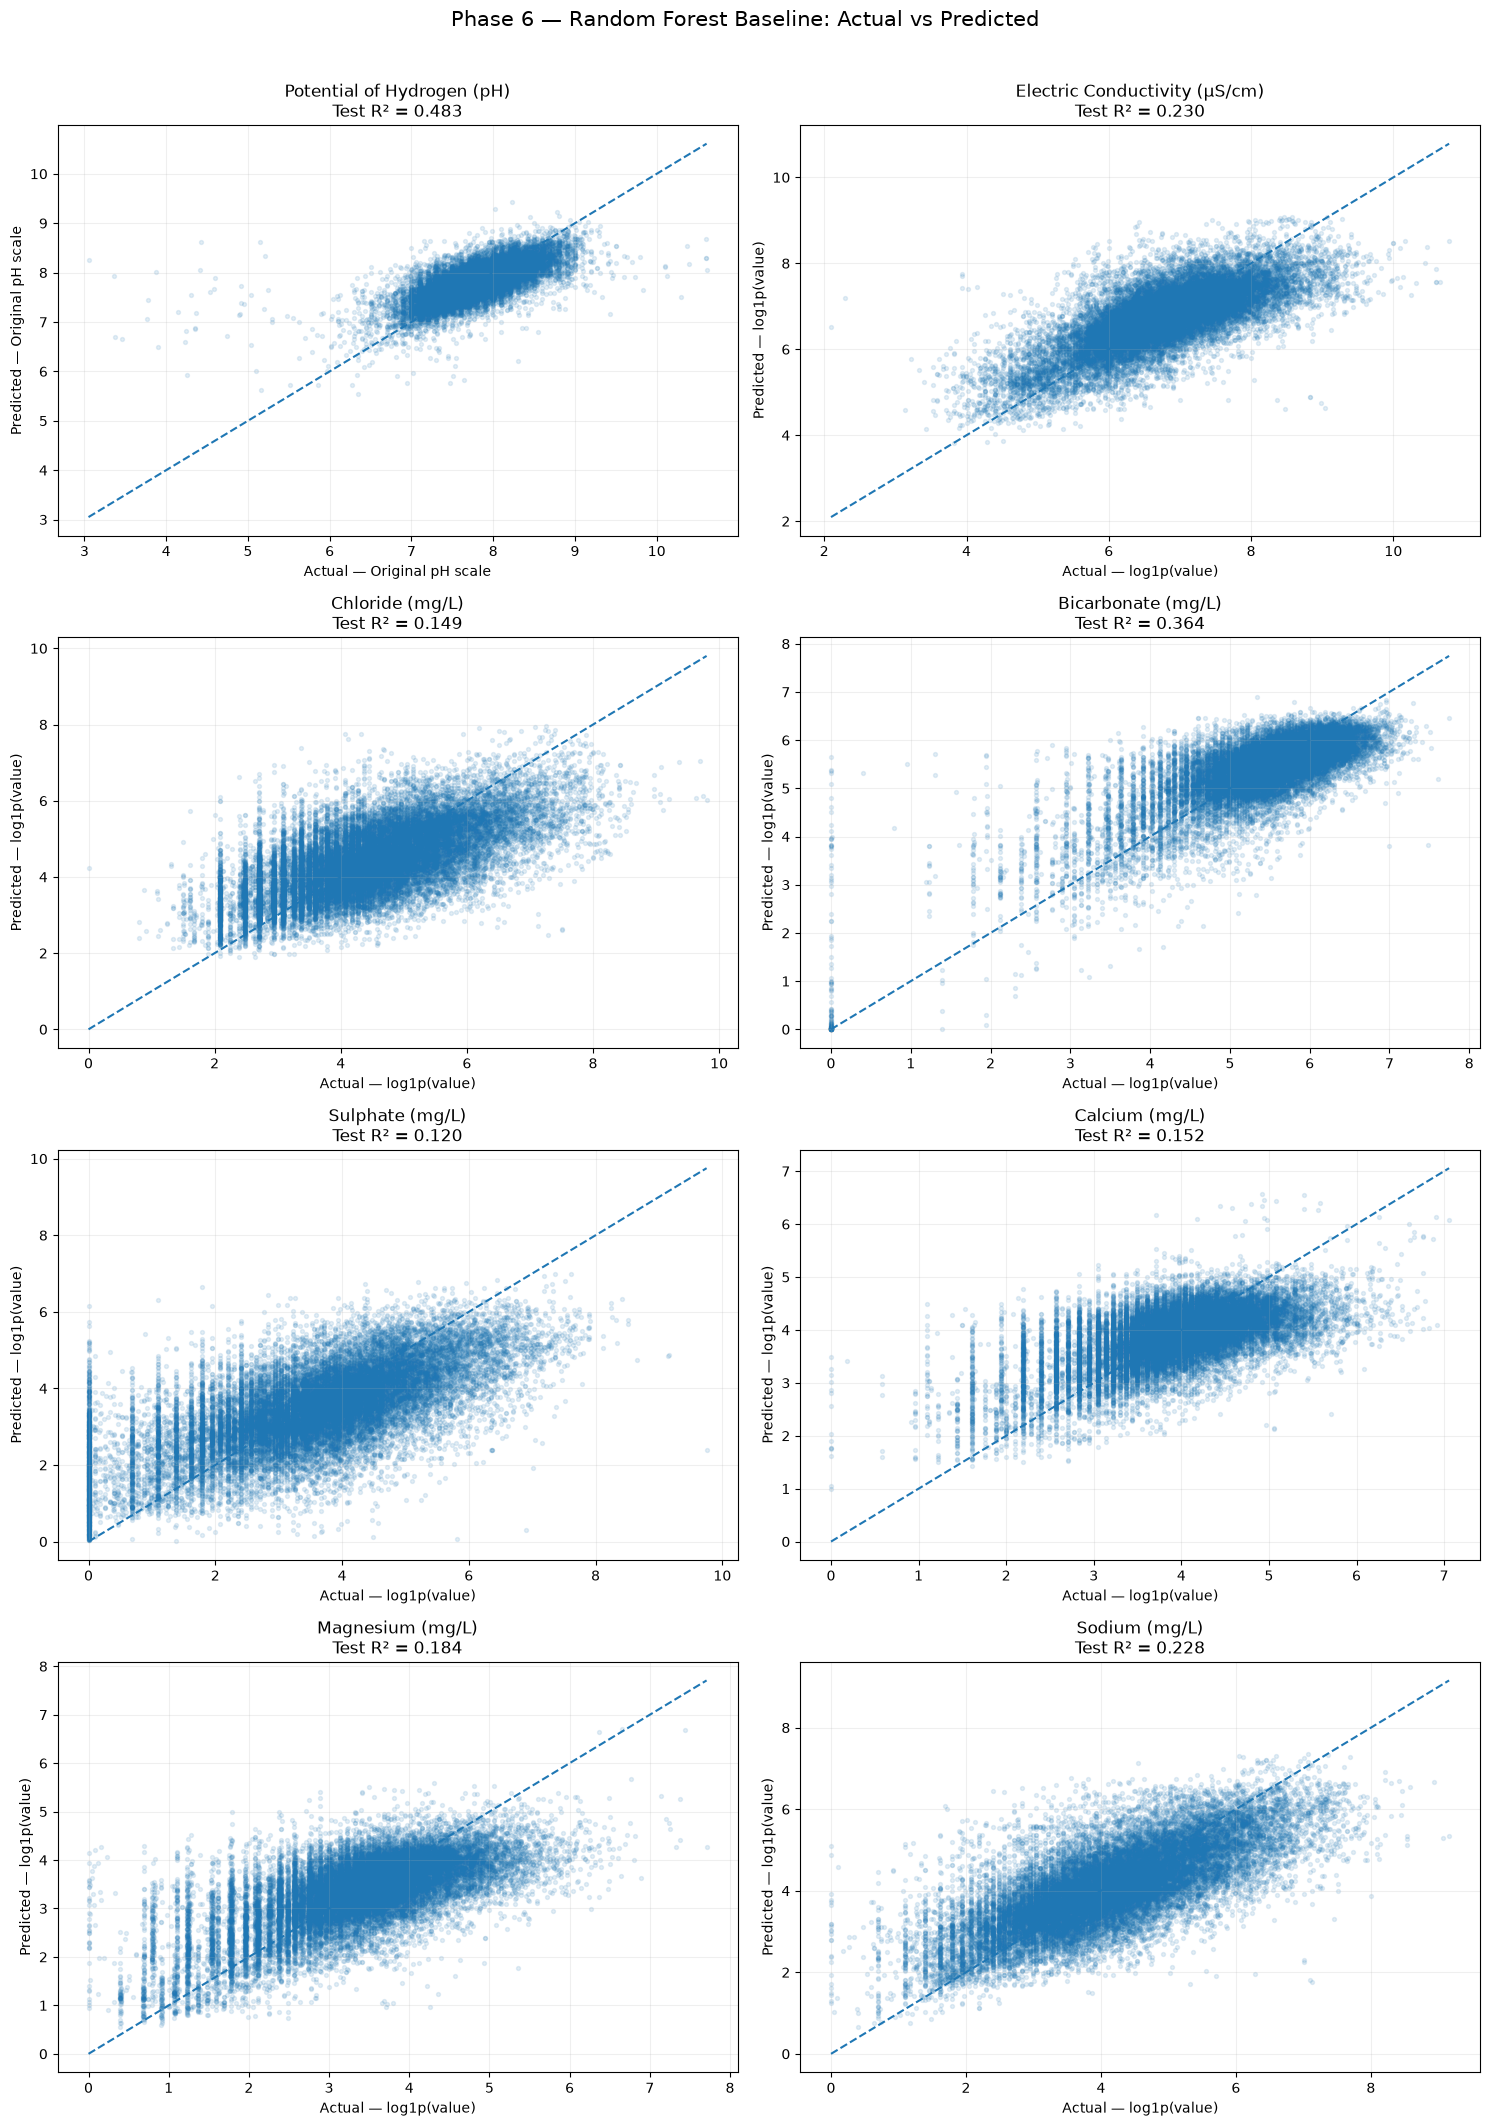

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(15, 21))
axes = axes.flatten()

for ax, target in zip(axes, TARGETS):

    actual = prediction_store[target]["Actual"].to_numpy()
    predicted = prediction_store[target]["Predicted"].to_numpy()

    if TARGET_TRANSFORMS[target] == "log1p":
        plot_actual = np.log1p(actual)
        plot_predicted = np.log1p(np.maximum(predicted, 0))
        axis_label = "log1p(value)"
    else:
        plot_actual = actual
        plot_predicted = predicted
        axis_label = "Original pH scale"

    ax.scatter(
        plot_actual,
        plot_predicted,
        alpha=0.12,
        s=8
    )

    lower = min(plot_actual.min(), plot_predicted.min())
    upper = max(plot_actual.max(), plot_predicted.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        linewidth=1.5
    )

    r2_value = evaluation_df.loc[target, "R2"]

    ax.set_title(f"{target}\nTest R² = {r2_value:.3f}")
    ax.set_xlabel(f"Actual — {axis_label}")
    ax.set_ylabel(f"Predicted — {axis_label}")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Phase 6 — Random Forest Baseline: Actual vs Predicted",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

In [17]:
# Create log-transformed chemical input features.
CHEM_LOG_FEATURES = {}

X_chem_full = X.copy()

for target in TARGETS:
    feature_name = f"_chem_log1p__{target}"

    X_chem_full[feature_name] = np.log1p(
        pd.to_numeric(model_df[target], errors="coerce")
    )

    CHEM_LOG_FEATURES[target] = feature_name

# Work exclusively within the existing training data.
X_chem_train = X_chem_full.iloc[train_idx].copy()

groups_train = groups.iloc[train_idx].reset_index(drop=True)

# Create a separate group-aware validation subset.
inner_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=77
)

inner_fit_idx, inner_val_idx = next(
    inner_splitter.split(X_train, groups=groups_train)
)

fit_groups = set(groups_train.iloc[inner_fit_idx])
validation_groups = set(groups_train.iloc[inner_val_idx])

X_context_fit = X_train.iloc[inner_fit_idx]
X_context_val = X_train.iloc[inner_val_idx]

print("INTERNAL SPATIAL VALIDATION SPLIT")
print("=" * 55)
print(f"Model-development records: {len(X_train):,}")
print(f"Inner training records:    {len(inner_fit_idx):,}")
print(f"Inner validation records:  {len(inner_val_idx):,}")
print(f"Inner training groups:     {len(fit_groups):,}")
print(f"Inner validation groups:  {len(validation_groups):,}")
print(f"Overlapping groups:        {len(fit_groups & validation_groups):,}")

assert len(fit_groups & validation_groups) == 0

# Confirm that every target has a corresponding chemistry input feature.
assert len(CHEM_LOG_FEATURES) == len(TARGETS)

print("\nChemical input features prepared:", len(CHEM_LOG_FEATURES))
print("Final test set remains unused in this comparison.")

INTERNAL SPATIAL VALIDATION SPLIT
Model-development records: 98,005
Inner training records:    78,322
Inner validation records:  19,683
Inner training groups:     13,945
Inner validation groups:  3,487
Overlapping groups:        0

Chemical input features prepared: 8
Final test set remains unused in this comparison.


In [18]:
VALIDATION_RF_SETTINGS = {
    "n_estimators": 60,
    "max_features": 0.7,
    "min_samples_leaf": 3,
    "max_samples": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

def build_model_preprocessor(numeric_columns):
    return ColumnTransformer([
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_columns
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=5
                ))
            ]),
            CATEGORICAL_FEATURES
        )
    ])

validation_results = []
validation_predictions = {}

print("CONTEXT-ONLY VS CHEMISTRY-ASSISTED TRAINING")
print("=" * 65)

for target in TARGETS:

    print(f"\nTARGET: {target}")

    y_fit = y_train_transformed[target].iloc[inner_fit_idx]
    y_val_original = y_train[target].iloc[inner_val_idx].to_numpy()

    # --------------------------------------------------
    # Model A: Context-only
    # --------------------------------------------------
    context_model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("regressor", RandomForestRegressor(
            **VALIDATION_RF_SETTINGS
        ))
    ])

    start = perf_counter()

    context_model.fit(
        X_context_fit,
        y_fit
    )

    context_time = perf_counter() - start

    context_pred_transformed = context_model.predict(
        X_context_val
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        context_pred = np.expm1(context_pred_transformed)
    else:
        context_pred = context_pred_transformed

    # --------------------------------------------------
    # Model B: Chemistry-assisted
    # --------------------------------------------------
    own_target_feature = CHEM_LOG_FEATURES[target]

    other_chemical_features = [
        CHEM_LOG_FEATURES[t]
        for t in TARGETS
        if t != target
    ]

    # Explicit leakage check: target is excluded.
    assert own_target_feature not in other_chemical_features

    assisted_numeric_features = (
        NUMERIC_FEATURES + other_chemical_features
    )

    assisted_feature_columns = (
        assisted_numeric_features + CATEGORICAL_FEATURES
    )

    assisted_preprocessor = build_model_preprocessor(
        assisted_numeric_features
    )

    assisted_model = Pipeline([
        ("preprocessing", assisted_preprocessor),
        ("regressor", RandomForestRegressor(
            **VALIDATION_RF_SETTINGS
        ))
    ])

    X_assisted_fit = X_chem_train.iloc[inner_fit_idx][
        assisted_feature_columns
    ]

    X_assisted_val = X_chem_train.iloc[inner_val_idx][
        assisted_feature_columns
    ]

    start = perf_counter()

    assisted_model.fit(
        X_assisted_fit,
        y_fit
    )

    assisted_time = perf_counter() - start

    assisted_pred_transformed = assisted_model.predict(
        X_assisted_val
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        assisted_pred = np.expm1(assisted_pred_transformed)
    else:
        assisted_pred = assisted_pred_transformed

    # --------------------------------------------------
    # Evaluate both approaches in original units.
    # --------------------------------------------------
    for model_name, predictions, elapsed in [
        ("Context-only", context_pred, context_time),
        ("Chemistry-assisted", assisted_pred, assisted_time)
    ]:

        validation_results.append({
            "Target": target,
            "Model": model_name,
            "MAE": mean_absolute_error(
                y_val_original, predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_val_original, predictions
            )),
            "R2": r2_score(
                y_val_original, predictions
            ),
            "Training time (seconds)": elapsed
        })

    validation_predictions[target] = pd.DataFrame({
        "Actual": y_val_original,
        "Context-only": context_pred,
        "Chemistry-assisted": assisted_pred
    })

    print(
        f"Context-only: {context_time:.1f}s | "
        f"Chemistry-assisted: {assisted_time:.1f}s"
    )

print("\nBoth prediction approaches trained for all eight targets.")

CONTEXT-ONLY VS CHEMISTRY-ASSISTED TRAINING

TARGET: Potential of Hydrogen (pH)
Context-only: 24.1s | Chemistry-assisted: 62.3s

TARGET: Electric Conductivity (μS/cm)
Context-only: 43.6s | Chemistry-assisted: 45.1s

TARGET: Chloride (mg/L)
Context-only: 47.1s | Chemistry-assisted: 51.3s

TARGET: Bicarbonate (mg/L)
Context-only: 40.7s | Chemistry-assisted: 49.3s

TARGET: Sulphate (mg/L)
Context-only: 40.6s | Chemistry-assisted: 51.2s

TARGET: Calcium (mg/L)
Context-only: 37.7s | Chemistry-assisted: 45.6s

TARGET: Magnesium (mg/L)
Context-only: 40.5s | Chemistry-assisted: 46.8s

TARGET: Sodium (mg/L)
Context-only: 42.8s | Chemistry-assisted: 47.0s

Both prediction approaches trained for all eight targets.


In [19]:
VALIDATION_RF_SETTINGS = {
    "n_estimators": 60,
    "max_features": 0.7,
    "min_samples_leaf": 3,
    "max_samples": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

def build_model_preprocessor(numeric_columns):
    return ColumnTransformer([
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_columns
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=5
                ))
            ]),
            CATEGORICAL_FEATURES
        )
    ])

validation_results = []
validation_predictions = {}

print("CONTEXT-ONLY VS CHEMISTRY-ASSISTED TRAINING")
print("=" * 65)

for target in TARGETS:

    print(f"\nTARGET: {target}")

    y_fit = y_train_transformed[target].iloc[inner_fit_idx]
    y_val_original = y_train[target].iloc[inner_val_idx].to_numpy()

    # --------------------------------------------------
    # Model A: Context-only
    # --------------------------------------------------
    context_model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("regressor", RandomForestRegressor(
            **VALIDATION_RF_SETTINGS
        ))
    ])

    start = perf_counter()

    context_model.fit(
        X_context_fit,
        y_fit
    )

    context_time = perf_counter() - start

    context_pred_transformed = context_model.predict(
        X_context_val
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        context_pred = np.expm1(context_pred_transformed)
    else:
        context_pred = context_pred_transformed

    # --------------------------------------------------
    # Model B: Chemistry-assisted
    # --------------------------------------------------
    own_target_feature = CHEM_LOG_FEATURES[target]

    other_chemical_features = [
        CHEM_LOG_FEATURES[t]
        for t in TARGETS
        if t != target
    ]

    # Explicit leakage check: target is excluded.
    assert own_target_feature not in other_chemical_features

    assisted_numeric_features = (
        NUMERIC_FEATURES + other_chemical_features
    )

    assisted_feature_columns = (
        assisted_numeric_features + CATEGORICAL_FEATURES
    )

    assisted_preprocessor = build_model_preprocessor(
        assisted_numeric_features
    )

    assisted_model = Pipeline([
        ("preprocessing", assisted_preprocessor),
        ("regressor", RandomForestRegressor(
            **VALIDATION_RF_SETTINGS
        ))
    ])

    X_assisted_fit = X_chem_train.iloc[inner_fit_idx][
        assisted_feature_columns
    ]

    X_assisted_val = X_chem_train.iloc[inner_val_idx][
        assisted_feature_columns
    ]

    start = perf_counter()

    assisted_model.fit(
        X_assisted_fit,
        y_fit
    )

    assisted_time = perf_counter() - start

    assisted_pred_transformed = assisted_model.predict(
        X_assisted_val
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        assisted_pred = np.expm1(assisted_pred_transformed)
    else:
        assisted_pred = assisted_pred_transformed

    # --------------------------------------------------
    # Evaluate both approaches in original units.
    # --------------------------------------------------
    for model_name, predictions, elapsed in [
        ("Context-only", context_pred, context_time),
        ("Chemistry-assisted", assisted_pred, assisted_time)
    ]:

        validation_results.append({
            "Target": target,
            "Model": model_name,
            "MAE": mean_absolute_error(
                y_val_original, predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_val_original, predictions
            )),
            "R2": r2_score(
                y_val_original, predictions
            ),
            "Training time (seconds)": elapsed
        })

    validation_predictions[target] = pd.DataFrame({
        "Actual": y_val_original,
        "Context-only": context_pred,
        "Chemistry-assisted": assisted_pred
    })

    print(
        f"Context-only: {context_time:.1f}s | "
        f"Chemistry-assisted: {assisted_time:.1f}s"
    )

print("\nBoth prediction approaches trained for all eight targets.")

CONTEXT-ONLY VS CHEMISTRY-ASSISTED TRAINING

TARGET: Potential of Hydrogen (pH)
Context-only: 23.0s | Chemistry-assisted: 61.5s

TARGET: Electric Conductivity (μS/cm)
Context-only: 42.2s | Chemistry-assisted: 42.9s

TARGET: Chloride (mg/L)
Context-only: 42.4s | Chemistry-assisted: 47.3s

TARGET: Bicarbonate (mg/L)
Context-only: 38.8s | Chemistry-assisted: 47.2s

TARGET: Sulphate (mg/L)
Context-only: 39.1s | Chemistry-assisted: 51.2s

TARGET: Calcium (mg/L)
Context-only: 37.5s | Chemistry-assisted: 45.7s

TARGET: Magnesium (mg/L)
Context-only: 40.7s | Chemistry-assisted: 45.1s

TARGET: Sodium (mg/L)
Context-only: 41.4s | Chemistry-assisted: 47.1s

Both prediction approaches trained for all eight targets.


In [20]:
validation_df = pd.DataFrame(validation_results)

mae_comparison = validation_df.pivot(
    index="Target",
    columns="Model",
    values="MAE"
)

r2_comparison = validation_df.pivot(
    index="Target",
    columns="Model",
    values="R2"
)

comparison_table = pd.DataFrame({
    "Context-only MAE": mae_comparison["Context-only"],
    "Chemistry-assisted MAE": mae_comparison["Chemistry-assisted"],
    "MAE improvement (%)": (
        (
            mae_comparison["Context-only"]
            - mae_comparison["Chemistry-assisted"]
        )
        / mae_comparison["Context-only"]
    ) * 100,
    "Context-only R2": r2_comparison["Context-only"],
    "Chemistry-assisted R2": r2_comparison["Chemistry-assisted"]
})

print("INTERNAL SPATIAL VALIDATION — MODEL COMPARISON")
print("=" * 80)
display(comparison_table.round(4))

print("\nPositive MAE improvement means chemistry-assisted prediction")
print("has lower error than context-only prediction.")
print("\nValidation records:", len(inner_val_idx))
print("Final independent test records:", len(X_test))

INTERNAL SPATIAL VALIDATION — MODEL COMPARISON


,Context-only MAE,Chemistry-assisted MAE,MAE improvement (%),Context-only R2,Chemistry-assisted R2
Target,,,,,
Bicarbonate (mg/L),109.0795,56.1257,48.5460,0.3201,0.7515
Calcium (mg/L),32.8328,16.5166,49.6947,0.1278,0.6755
Chloride (mg/L),155.4691,36.2483,76.6846,0.1441,0.8928
Electric Conductivity (μS/cm),697.2168,115.6810,83.4082,0.2092,0.8592
Magnesium (mg/L),25.5160,11.2295,55.9905,0.1679,0.6951
Potential of Hydrogen (pH),0.2304,0.2267,1.5832,0.4810,0.5211
Sodium (mg/L),101.0301,25.7044,74.5577,0.2255,0.8747
Sulphate (mg/L),76.1040,42.9255,43.5962,0.1478,0.6941



Positive MAE improvement means chemistry-assisted prediction
has lower error than context-only prediction.

Validation records: 19683
Final independent test records: 24708


In [21]:
# Use the complete Phase 3 master dataset (all 174,635 records).
chemical_values = master_df[TARGETS].apply(
    pd.to_numeric,
    errors="coerce"
)

# A valid model input must be present, finite and nonnegative.
valid_chemical = (
    chemical_values.notna()
    & np.isfinite(chemical_values)
    & chemical_values.ge(0)
)

coverage_rows = []

for target in TARGETS:

    # Chemistry-assisted model requires the other seven analytes.
    other_targets = [t for t in TARGETS if t != target]

    seven_inputs_available = valid_chemical[other_targets].all(axis=1)

    target_observed = valid_chemical[target]

    coverage_rows.append({
        "Target to estimate": target,
        "Records with all 7 inputs": int(seven_inputs_available.sum()),
        "Input coverage (%)": (
            seven_inputs_available.mean() * 100
        ),
        "Target also observed": int(
            (seven_inputs_available & target_observed).sum()
        ),
        "Potential missing-target cases": int(
            (seven_inputs_available & ~target_observed).sum()
        )
    })

coverage_df = pd.DataFrame(
    coverage_rows
).set_index("Target to estimate")

print("CHEMISTRY-ASSISTED INPUT AVAILABILITY")
print("=" * 75)
print(f"Original nationwide records: {len(master_df):,}")
display(coverage_df.round(2))

print("\nNote: All seven other chemical measurements must be")
print("available and nonnegative for this strict coverage estimate.")
print("No data has been removed or modified.")

CHEMISTRY-ASSISTED INPUT AVAILABILITY
Original nationwide records: 174,635


,Records with all 7 inputs,Input coverage (%),Target also observed,Potential missing-target cases
Target to estimate,,,,
Potential of Hydrogen (pH),122846,70.34,122723,123
Electric Conductivity (μS/cm),122741,70.28,122723,18
Chloride (mg/L),123060,70.47,122723,337
Bicarbonate (mg/L),122842,70.34,122723,119
Sulphate (mg/L),141521,81.04,122723,18798
Calcium (mg/L),122753,70.29,122723,30
Magnesium (mg/L),122836,70.34,122723,113
Sodium (mg/L),123980,70.99,122723,1257



Note: All seven other chemical measurements must be
available and nonnegative for this strict coverage estimate.
No data has been removed or modified.


In [22]:
PH_TARGET = "Potential of Hydrogen (pH)"

master_targets = master_df[TARGETS].apply(
    pd.to_numeric, errors="coerce"
)

# Initial validity rule: finite, nonnegative observations.
valid_targets = (
    master_targets.notna()
    & np.isfinite(master_targets)
    & master_targets.ge(0)
)

# Apply the pH screening rule used for modelling.
ph_values = master_targets[PH_TARGET]
valid_targets[PH_TARGET] = (
    ph_values.notna()
    & np.isfinite(ph_values)
    & ph_values.gt(0)
    & ph_values.le(14)
)

# Compare original counts with the stricter validity rule.
loose_complete = (
    master_targets.notna()
    & np.isfinite(master_targets)
    & master_targets.ge(0)
).all(axis=1)

strict_complete = valid_targets.all(axis=1)

core_ids = set(model_df["_record_id"].astype(str))
strict_ids = set(
    master_df.loc[strict_complete, "_record_id"].astype(str)
)

print("RECORD COUNT RECONCILIATION")
print("=" * 60)
print(f"Original master records:                 {len(master_df):,}")
print(f"All 8 nonnegative finite targets:        {loose_complete.sum():,}")
print(f"All 8 targets after pH screening:        {strict_complete.sum():,}")
print(f"Phase 5 core modelling records:          {len(model_df):,}")
print(f"Core records missing from strict set:    {len(core_ids - strict_ids):,}")
print(f"Strict records absent from core dataset: {len(strict_ids - core_ids):,}")

print("\nPH VALUE SCREENING")
print("-" * 60)
print(f"Missing pH:          {ph_values.isna().sum():,}")
print(f"pH equal to zero:    {(ph_values == 0).sum():,}")
print(f"pH below zero:       {(ph_values < 0).sum():,}")
print(f"pH above 14:         {(ph_values > 14).sum():,}")

# Recalculate chemistry-assisted coverage using the stricter validity rule.
corrected_coverage = []

for target in TARGETS:
    other_targets = [t for t in TARGETS if t != target]

    inputs_available = valid_targets[other_targets].all(axis=1)

    target_missing = master_targets[target].isna()
    target_invalid = (
        master_targets[target].notna()
        & ~valid_targets[target]
    )

    corrected_coverage.append({
        "Target": target,
        "Seven inputs available": int(inputs_available.sum()),
        "Target observed and valid": int(
            (inputs_available & valid_targets[target]).sum()
        ),
        "Target genuinely missing": int(
            (inputs_available & target_missing).sum()
        ),
        "Target present but invalid": int(
            (inputs_available & target_invalid).sum()
        )
    })

corrected_coverage_df = pd.DataFrame(
    corrected_coverage
).set_index("Target")

print("\nCORRECTED CHEMISTRY-ASSISTED COVERAGE")
display(corrected_coverage_df)

RECORD COUNT RECONCILIATION
Original master records:                 174,635
All 8 nonnegative finite targets:        122,723
All 8 targets after pH screening:        122,713
Phase 5 core modelling records:          122,713
Core records missing from strict set:    0
Strict records absent from core dataset: 0

PH VALUE SCREENING
------------------------------------------------------------
Missing pH:          11,906
pH equal to zero:    4
pH below zero:       0
pH above 14:         6

CORRECTED CHEMISTRY-ASSISTED COVERAGE


,Seven inputs available,Target observed and valid,Target genuinely missing,Target present but invalid
Target,,,,
Potential of Hydrogen (pH),122846,122713,123,10
Electric Conductivity (μS/cm),122731,122713,18,0
Chloride (mg/L),123050,122713,337,0
Bicarbonate (mg/L),122832,122713,119,0
Sulphate (mg/L),141511,122713,18796,2
Calcium (mg/L),122743,122713,30,0
Magnesium (mg/L),122826,122713,107,6
Sodium (mg/L),123970,122713,1257,0


In [23]:
final_assisted_models = {}
final_assisted_training_times = {}

print("FINAL CHEMISTRY-ASSISTED MODEL TRAINING")
print("=" * 65)

for target in TARGETS:

    print(f"\nTraining: {target}")

    own_target_feature = CHEM_LOG_FEATURES[target]

    other_chemical_features = [
        CHEM_LOG_FEATURES[t]
        for t in TARGETS
        if t != target
    ]

    assisted_numeric_features = (
        NUMERIC_FEATURES + other_chemical_features
    )

    assisted_feature_columns = (
        assisted_numeric_features + CATEGORICAL_FEATURES
    )

    # Verify the target itself is not included as an input.
    assert own_target_feature not in assisted_feature_columns

    assisted_preprocessor = build_model_preprocessor(
        assisted_numeric_features
    )

    assisted_model = Pipeline([
        ("preprocessing", assisted_preprocessor),
        ("regressor", RandomForestRegressor(**MODEL_SETTINGS))
    ])

    X_assisted_train = X_chem_full.iloc[train_idx][
        assisted_feature_columns
    ]

    start_time = perf_counter()

    assisted_model.fit(
        X_assisted_train,
        y_train_transformed[target]
    )

    elapsed = perf_counter() - start_time

    final_assisted_models[target] = assisted_model
    final_assisted_training_times[target] = elapsed

    print(f"Completed in {elapsed:.2f} seconds")

print("\nAll eight final chemistry-assisted models trained.")

display(pd.DataFrame({
    "Target": TARGETS,
    "Trees": [MODEL_SETTINGS["n_estimators"]] * len(TARGETS),
    "Training time (seconds)": [
        final_assisted_training_times[t] for t in TARGETS
    ]
}).set_index("Target").round(2))

FINAL CHEMISTRY-ASSISTED MODEL TRAINING

Training: Potential of Hydrogen (pH)
Completed in 281.77 seconds

Training: Electric Conductivity (μS/cm)
Completed in 187.09 seconds

Training: Chloride (mg/L)
Completed in 206.79 seconds

Training: Bicarbonate (mg/L)
Completed in 203.63 seconds

Training: Sulphate (mg/L)
Completed in 224.13 seconds

Training: Calcium (mg/L)
Completed in 193.81 seconds

Training: Magnesium (mg/L)
Completed in 191.38 seconds

Training: Sodium (mg/L)
Completed in 201.60 seconds

All eight final chemistry-assisted models trained.


,Trees,Training time (seconds)
Target,,
Potential of Hydrogen (pH),150,281.77
Electric Conductivity (μS/cm),150,187.09
Chloride (mg/L),150,206.79
Bicarbonate (mg/L),150,203.63
Sulphate (mg/L),150,224.13
Calcium (mg/L),150,193.81
Magnesium (mg/L),150,191.38
Sodium (mg/L),150,201.60


In [24]:
final_comparison_rows = []
final_comparison_predictions = {}

for target in TARGETS:

    # Existing context-only model predictions.
    context_pred = prediction_store[target]["Predicted"].to_numpy()

    # Chemistry-assisted input features, excluding the target itself.
    other_chemical_features = [
        CHEM_LOG_FEATURES[t]
        for t in TARGETS
        if t != target
    ]

    assisted_numeric_features = (
        NUMERIC_FEATURES + other_chemical_features
    )

    assisted_feature_columns = (
        assisted_numeric_features + CATEGORICAL_FEATURES
    )

    X_assisted_test = X_chem_full.iloc[test_idx][
        assisted_feature_columns
    ]

    assisted_pred_transformed = (
        final_assisted_models[target].predict(X_assisted_test)
    )

    if TARGET_TRANSFORMS[target] == "log1p":
        assisted_pred = np.expm1(assisted_pred_transformed)
    else:
        assisted_pred = assisted_pred_transformed

    actual = y_test[target].to_numpy()

    context_mae = mean_absolute_error(actual, context_pred)
    assisted_mae = mean_absolute_error(actual, assisted_pred)

    context_rmse = np.sqrt(
        mean_squared_error(actual, context_pred)
    )

    assisted_rmse = np.sqrt(
        mean_squared_error(actual, assisted_pred)
    )

    context_r2 = r2_score(actual, context_pred)
    assisted_r2 = r2_score(actual, assisted_pred)

    final_comparison_rows.append({
        "Target": target,
        "Context MAE": context_mae,
        "Assisted MAE": assisted_mae,
        "MAE improvement (%)": (
            (context_mae - assisted_mae) / context_mae
        ) * 100,
        "Context RMSE": context_rmse,
        "Assisted RMSE": assisted_rmse,
        "Context R2": context_r2,
        "Assisted R2": assisted_r2
    })

    final_comparison_predictions[target] = pd.DataFrame({
        "Actual": actual,
        "Context-only": context_pred,
        "Chemistry-assisted": assisted_pred
    })

final_comparison_df = (
    pd.DataFrame(final_comparison_rows)
    .set_index("Target")
)

print("FINAL SPATIAL TEST-SET COMPARISON")
print("=" * 85)
display(final_comparison_df.round(4))

print("\nTest records:", len(X_test))
print("Test spatial groups:", len(test_groups))
print("Spatial group overlap:", len(train_groups & test_groups))

print("\nBoth model approaches evaluated on the same held-out records.")

FINAL SPATIAL TEST-SET COMPARISON


,Context MAE,Assisted MAE,MAE improvement (%),Context RMSE,Assisted RMSE,Context R2,Assisted R2
Target,,,,,,,
Potential of Hydrogen (pH),0.2255,0.2216,1.7010,0.3227,0.3038,0.4828,0.5418
Electric Conductivity (μS/cm),646.9939,99.2824,84.6548,1499.4387,414.0321,0.2304,0.9413
Chloride (mg/L),143.9307,32.5106,77.4124,435.9246,129.8359,0.1492,0.9245
Bicarbonate (mg/L),100.7022,51.0159,49.3399,148.8788,88.9855,0.3639,0.7727
Sulphate (mg/L),70.8188,39.8250,43.7649,239.5333,167.4453,0.1204,0.5702
Calcium (mg/L),31.7489,15.1761,52.1997,59.8059,33.0536,0.1523,0.7411
Magnesium (mg/L),24.6047,10.5780,57.0084,57.0753,34.0365,0.1835,0.7096
Sodium (mg/L),90.9004,22.0624,75.7290,250.1224,76.1191,0.2275,0.9285



Test records: 24708
Test spatial groups: 4359
Spatial group overlap: 0

Both model approaches evaluated on the same held-out records.


In [25]:
print("FINAL SPATIAL TEST-SET COMPARISON")
display(final_comparison_df.round(4))

FINAL SPATIAL TEST-SET COMPARISON


,Context MAE,Assisted MAE,MAE improvement (%),Context RMSE,Assisted RMSE,Context R2,Assisted R2
Target,,,,,,,
Potential of Hydrogen (pH),0.2255,0.2216,1.7010,0.3227,0.3038,0.4828,0.5418
Electric Conductivity (μS/cm),646.9939,99.2824,84.6548,1499.4387,414.0321,0.2304,0.9413
Chloride (mg/L),143.9307,32.5106,77.4124,435.9246,129.8359,0.1492,0.9245
Bicarbonate (mg/L),100.7022,51.0159,49.3399,148.8788,88.9855,0.3639,0.7727
Sulphate (mg/L),70.8188,39.8250,43.7649,239.5333,167.4453,0.1204,0.5702
Calcium (mg/L),31.7489,15.1761,52.1997,59.8059,33.0536,0.1523,0.7411
Magnesium (mg/L),24.6047,10.5780,57.0084,57.0753,34.0365,0.1835,0.7096
Sodium (mg/L),90.9004,22.0624,75.7290,250.1224,76.1191,0.2275,0.9285


In [26]:
importance_rows = []

model_collections = {
    "Context-only": trained_models,
    "Chemistry-assisted": final_assisted_models
}

for model_type, model_collection in model_collections.items():

    for target, pipeline in model_collection.items():

        preprocessing = pipeline.named_steps["preprocessing"]
        regressor = pipeline.named_steps["regressor"]

        feature_names = preprocessing.get_feature_names_out()
        importances = regressor.feature_importances_

        if len(feature_names) != len(importances):
            raise ValueError(
                f"Feature importance mismatch for {model_type}, {target}"
            )

        top_indices = np.argsort(importances)[::-1][:15]

        for rank, idx in enumerate(top_indices, start=1):
            importance_rows.append({
                "Model": model_type,
                "Target": target,
                "Rank": rank,
                "Feature": feature_names[idx],
                "Importance": importances[idx]
            })

feature_importance_df = pd.DataFrame(importance_rows)

print("TOP THREE PREDICTIVE FEATURES PER MODEL")
print("=" * 75)

display(
    feature_importance_df[
        feature_importance_df["Rank"] <= 3
    ].round(5)
)

print("\nFeature importance extracted for all 16 models.")

TOP THREE PREDICTIVE FEATURES PER MODEL


,Model,Target,Rank,Feature,Importance
0,Context-only,Potential of Hydrogen (pH),1,numeric___latitude,0.25811
1,Context-only,Potential of Hydrogen (pH),2,numeric___longitude,0.19851
2,Context-only,Potential of Hydrogen (pH),3,numeric___year_index,0.19475
15,Context-only,Electric Conductivity (μS/cm),1,numeric___longitude,0.32780
16,Context-only,Electric Conductivity (μS/cm),2,numeric___latitude,0.23458
17,Context-only,Electric Conductivity (μS/cm),3,categorical___state_feature_kerala,0.09995
30,Context-only,Chloride (mg/L),1,numeric___longitude,0.31117
31,Context-only,Chloride (mg/L),2,numeric___latitude,0.26935
32,Context-only,Chloride (mg/L),3,numeric___year_index,0.08824
45,Context-only,Bicarbonate (mg/L),1,numeric___longitude,0.21855



Feature importance extracted for all 16 models.


In [27]:
import joblib
import sklearn

# Dedicated Phase 6 directories
MODEL_DIR = PROJECT_ROOT / "models" / "phase_6"
REPORT_DIR = PROJECT_ROOT / "reports" / "modeling" / "phase_6"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Build input feature schemas for each chemistry-assisted model.
assisted_input_columns = {}

for target in TARGETS:
    other_features = [
        CHEM_LOG_FEATURES[t]
        for t in TARGETS
        if t != target
    ]

    assisted_input_columns[target] = (
        NUMERIC_FEATURES
        + other_features
        + CATEGORICAL_FEATURES
    )

# Create a reproducible model bundle.
model_bundle = {
    "project": "Borewell Sentinel India",
    "phase": 6,
    "phase_name": "Multi-Contaminant Prediction",

    "targets": TARGETS,
    "target_transformations": TARGET_TRANSFORMS,

    "context_numeric_features": NUMERIC_FEATURES,
    "context_categorical_features": CATEGORICAL_FEATURES,

    "chemistry_feature_map": CHEM_LOG_FEATURES,
    "chemistry_assisted_input_columns": assisted_input_columns,

    "context_only_models": trained_models,
    "chemistry_assisted_models": final_assisted_models,

    "context_model_settings": MODEL_SETTINGS,

    "validation": {
        "method": "GroupShuffleSplit",
        "random_state": 42,
        "test_size": 0.20,
        "training_records": len(X_train),
        "testing_records": len(X_test),
        "training_spatial_groups": len(train_groups),
        "testing_spatial_groups": len(test_groups),
        "overlapping_spatial_groups": len(train_groups & test_groups)
    },

    "environment": {
        "python_version": __import__("sys").version,
        "pandas_version": pd.__version__,
        "numpy_version": np.__version__,
        "scikit_learn_version": sklearn.__version__
    }
}

MODEL_PATH = MODEL_DIR / "phase6_model_bundle.joblib"

joblib.dump(model_bundle, MODEL_PATH, compress=3)

# Save final model comparison.
metrics_export = final_comparison_df.reset_index()

metrics_export["Context training time (seconds)"] = [
    training_times[t] for t in TARGETS
]

metrics_export["Assisted training time (seconds)"] = [
    final_assisted_training_times[t] for t in TARGETS
]

metrics_export.to_csv(
    REPORT_DIR / "phase6_final_model_comparison.csv",
    index=False
)

# Save test predictions with record traceability.
prediction_export = model_df.iloc[test_idx][
    [
        "_record_id",
        "_spatial_group_id",
        "_state_feature",
        "_district_feature"
    ]
].reset_index(drop=True)

for target in TARGETS:
    prediction_data = final_comparison_predictions[target]

    prediction_export[f"{target} - Actual"] = (
        prediction_data["Actual"].to_numpy()
    )

    prediction_export[f"{target} - Context prediction"] = (
        prediction_data["Context-only"].to_numpy()
    )

    prediction_export[f"{target} - Assisted prediction"] = (
        prediction_data["Chemistry-assisted"].to_numpy()
    )

prediction_export.to_csv(
    REPORT_DIR / "phase6_test_predictions.csv",
    index=False
)

# Save interpretation and diagnostic reports.
feature_importance_df.to_csv(
    REPORT_DIR / "phase6_feature_importance.csv",
    index=False
)

residual_summary.to_csv(
    REPORT_DIR / "phase6_residual_diagnostics.csv"
)

range_error_summary.to_csv(
    REPORT_DIR / "phase6_error_by_value_range.csv",
    index=False
)

corrected_coverage_df.to_csv(
    REPORT_DIR / "phase6_chemistry_assisted_coverage.csv"
)

print("PHASE 6 ARTIFACTS SAVED")
print("=" * 65)

for path in [
    MODEL_PATH,
    REPORT_DIR / "phase6_final_model_comparison.csv",
    REPORT_DIR / "phase6_test_predictions.csv",
    REPORT_DIR / "phase6_feature_importance.csv",
    REPORT_DIR / "phase6_residual_diagnostics.csv",
    REPORT_DIR / "phase6_error_by_value_range.csv",
    REPORT_DIR / "phase6_chemistry_assisted_coverage.csv"
]:
    print(
        f"{path.relative_to(PROJECT_ROOT)} "
        f"| {path.stat().st_size / (1024**2):.2f} MB"
    )

print("\nModel bundle and six report files saved successfully.")

PHASE 6 ARTIFACTS SAVED
models\phase_6\phase6_model_bundle.joblib | 1802.74 MB
reports\modeling\phase_6\phase6_final_model_comparison.csv | 0.00 MB
reports\modeling\phase_6\phase6_test_predictions.csv | 10.94 MB
reports\modeling\phase_6\phase6_feature_importance.csv | 0.02 MB
reports\modeling\phase_6\phase6_residual_diagnostics.csv | 0.00 MB
reports\modeling\phase_6\phase6_error_by_value_range.csv | 0.00 MB
reports\modeling\phase_6\phase6_chemistry_assisted_coverage.csv | 0.00 MB

Model bundle and six report files saved successfully.


In [28]:
expected_files = [
    MODEL_PATH,
    REPORT_DIR / "phase6_final_model_comparison.csv",
    REPORT_DIR / "phase6_test_predictions.csv",
    REPORT_DIR / "phase6_feature_importance.csv",
    REPORT_DIR / "phase6_residual_diagnostics.csv",
    REPORT_DIR / "phase6_error_by_value_range.csv",
    REPORT_DIR / "phase6_chemistry_assisted_coverage.csv"
]

verification = pd.DataFrame({
    "Artifact": [p.name for p in expected_files],
    "Exists": [p.exists() for p in expected_files],
    "Size (MB)": [
        round(p.stat().st_size / (1024**2), 3) if p.exists() else None
        for p in expected_files
    ]
})

display(verification)

assert all(verification["Exists"]), "One or more artifacts are missing."

# Reload the saved bundle to verify serialization.
loaded_bundle = joblib.load(MODEL_PATH)

assert len(loaded_bundle["context_only_models"]) == 8
assert len(loaded_bundle["chemistry_assisted_models"]) == 8
assert loaded_bundle["validation"]["overlapping_spatial_groups"] == 0

print("\nArtifact verification PASSED.")
print("All 16 trained models successfully reloaded.")

,Artifact,Exists,Size (MB)
0,phase6_model_bundle.joblib,True,1802.736
1,phase6_final_model_comparison.csv,True,0.002
2,phase6_test_predictions.csv,True,10.939
3,phase6_feature_importance.csv,True,0.021
4,phase6_residual_diagnostics.csv,True,0.001
5,phase6_error_by_value_range.csv,True,0.003
6,phase6_chemistry_assisted_coverage.csv,True,0.000



Artifact verification PASSED.
All 16 trained models successfully reloaded.


---

# Phase 6 — Completion Report

## Objective achieved
Developed and evaluated nationwide multi-contaminant prediction models for eight core groundwater chemical parameters.

## Dataset
- Complete-case records: 122,713
- Training records: 98,005
- Independent testing records: 24,708
- Training spatial groups: 17,432
- Testing spatial groups: 4,359
- Spatial group overlap: 0

## Models developed
1. Context-only Random Forest regression models.
2. Chemistry-assisted Random Forest regression models.

Eight independent target models were trained for each prediction approach.

## Principal findings
- All eight chemistry-assisted models outperformed their corresponding context-only models.
- Chemistry-assisted MAE improvements ranged from 1.70% to 84.65%.
- The strongest chemistry-assisted test R² was 0.9413 for Electrical Conductivity.
- Sulphate was identified as the strongest missing-parameter estimation opportunity, with 18,796 potential missing-target cases in the nationwide dataset.

## Important limitations
- Evaluation used one spatial-group-aware train/test split.
- Chemistry-assisted performance applies to samples where the other seven core chemical inputs are available.
- Performance for partially observed chemical inputs has not yet been validated.
- Extreme source observations were retained and require further sensitivity analysis.
- These predictions are estimates, not replacements for laboratory measurements.
- Further validation and robustness testing remain part of Phase 9.

## Saved artifacts
- `models/phase_6/phase6_model_bundle.joblib`
- `reports/modeling/phase_6/phase6_final_model_comparison.csv`
- `reports/modeling/phase_6/phase6_test_predictions.csv`
- `reports/modeling/phase_6/phase6_feature_importance.csv`
- `reports/modeling/phase_6/phase6_residual_diagnostics.csv`
- `reports/modeling/phase_6/phase6_error_by_value_range.csv`
- `reports/modeling/phase_6/phase6_chemistry_assisted_coverage.csv`

## Phase status
COMPLETED — Phase 6 of 11.